<a href="https://colab.research.google.com/github/castr1x/ML_an.nykoliuk_3-12/blob/main/%D0%9B%D0%912_%D0%9C%D0%9D_%D0%97%D0%B0%D0%B2%D0%B4%D0%B0%D0%BD%D0%BD%D1%8F_1_%D0%9D%D0%B8%D0%BA%D0%BE%D0%BB%D1%8E%D0%BA_%D0%A4%D0%86%D0%A2_3_12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота 2. Николюк, ФІТ 3-12

# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

1. Вивести перші 5 рядків датасета

In [435]:
import numpy as np
import pandas as pd
import requests

In [436]:
resp = requests.get('https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)', headers={'User-agent':'123'}).text
tables = pd.read_html(resp)

df = tables[2]
df.head()

/tmp/ipykernel_1128/1189354424.py:2: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tables = pd.read_html(resp)


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


2.	Визначити розмір датасета.

In [437]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222 entries, 0 to 221
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Country/Territory         222 non-null    object
 1   IMF (2026)[1]             222 non-null    object
 2   World Bank (2025)[6]      222 non-null    object
 3   United Nations (2024)[7]  222 non-null    object
dtypes: object(4)
memory usage: 7.1+ KB


 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [438]:

new_cols = {
        'Country/Territory':'Country',
        'IMF (2026)[1]' : 'IMF_2026',
        "World Bank (2025)[6]":"World_bank_2025",
        "United Nations (2024)[7]":"UN_2024",
        }

df.rename(columns=new_cols, inplace=True)

In [439]:
df.drop(df[df.iloc[:,0]== "World"].index,inplace=True)

In [440]:
df

,Country,IMF_2026,World_bank_2025,UN_2024
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211
5,United Kingdom,4264794,4002588,3685881
...,...,...,...,...
217,Palau,377,345,310
218,Marshall Islands,342,308,281
219,Nauru,196,176,187
220,Montserrat,—N/a,—N/a,81


In [441]:
for i in range(1,4):
  df[df.columns[i]]= pd.to_numeric(df[df.columns[i]],errors='coerce')

In [442]:
df.dtypes

,0
Country,object
IMF_2026,float64
World_bank_2025,float64
UN_2024,float64


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [443]:
df.isna().sum()

,0
Country,0
IMF_2026,31
World_bank_2025,35
UN_2024,9


In [444]:
# %%timeit
for i in range(1,4):
  df[df.columns[i]].fillna(df[df.columns[i]].mean(),inplace=True)


/tmp/ipykernel_1128/321916609.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[df.columns[i]].fillna(df[df.columns[i]].mean(),inplace=True)


In [445]:
df

,Country,IMF_2026,World_bank_2025,UN_2024
1,United States,3.238392e+07,3.076970e+07,29298000.0
2,China[n 1],2.085159e+07,1.949804e+07,18743802.0
3,Germany,5.452858e+06,5.050923e+06,4659929.0
4,Japan,4.379253e+06,4.435163e+06,4026211.0
5,United Kingdom,4.264794e+06,4.002588e+06,3685881.0
...,...,...,...,...
217,Palau,3.770000e+02,3.450000e+02,310.0
218,Marshall Islands,3.420000e+02,3.080000e+02,281.0
219,Nauru,1.960000e+02,1.760000e+02,187.0
220,Montserrat,6.614603e+05,6.260497e+05,81.0


In [446]:
df.isna().sum()

,0
Country,0
IMF_2026,0
World_bank_2025,0
UN_2024,0


5. Ще раз вивести датасет

In [447]:
df.head()

,Country,IMF_2026,World_bank_2025,UN_2024
1,United States,32383920.0,30769700.0,29298000.0
2,China[n 1],20851593.0,19498039.0,18743802.0
3,Germany,5452858.0,5050923.0,4659929.0
4,Japan,4379253.0,4435163.0,4026211.0
5,United Kingdom,4264794.0,4002588.0,3685881.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [448]:
df.duplicated().sum()

np.int64(0)

7.	Вивести описову статистику датасету describe()

In [449]:
df.describe()

,IMF_2026,World_bank_2025,UN_2024
count,2.210000e+02,2.210000e+02,2.210000e+02
mean,6.614603e+05,6.260497e+05,5.224912e+05
std,2.666759e+06,2.520399e+06,2.410079e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,1.895900e+04,1.992800e+04,8.840000e+03
50%,1.020420e+05,9.977400e+04,4.276500e+04
75%,6.614603e+05,6.260497e+05,2.986970e+05
max,3.238392e+07,3.076970e+07,2.929800e+07


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [450]:
df['diff'] = abs(df['IMF_2026'] - df['World_bank_2025'])
answer = df.loc[df['diff'].idxmax(),['Country','diff']].to_list()
print(f"Найбільша різниця у {answer[0]}, вона становить {answer[1]}")

Найбільша різниця у United States, вона становить 1614220.0


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [451]:
corr_tab = df.iloc[:,1:4].corr()

corr_tab

,IMF_2026,World_bank_2025,UN_2024
IMF_2026,1.000000,0.998639,0.997343
World_bank_2025,0.998639,1.000000,0.997011
UN_2024,0.997343,0.997011,1.000000


In [452]:
for i in corr_tab.columns:
  print(i, corr_tab[corr_tab[i]<1][i].idxmax(), sep = ' ---> ')

IMF_2026 ---> World_bank_2025
World_bank_2025 ---> IMF_2026
UN_2024 ---> IMF_2026


Обчислити середнє значення за стовпцями

In [453]:
means = df.agg(
    dict(zip(df.columns[1::],list('mean' for i in range(len(df.columns)))
    ))

)

means

,0
IMF_2026,661460.289474
World_bank_2025,626049.693548
UN_2024,522491.207547
diff,70279.390992


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [454]:
df['std'] = df.iloc[:,1:].std(axis = 1)

In [455]:
answer = df.loc[df['std'].idxmax(),'Country']

print(f"Найбільше стандартне відхилення між аоказниками у {answer}")

Найбільше стандартне відхилення між аоказниками у United States


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [456]:
# df.groupby('Country')[['UN_2024', 'IMF_2026', 'World_bank_2025']].agg(['min','max']).idxmax()

by_country = df.set_index('Country')[['UN_2024', 'IMF_2026', 'World_bank_2025']]
result = pd.DataFrame({
    'min': by_country.idxmin(),
    'max': by_country.idxmax()
}
)
result

,min,max
UN_2024,Tuvalu,United States
IMF_2026,Tuvalu,United States
World_bank_2025,Tuvalu,United States


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

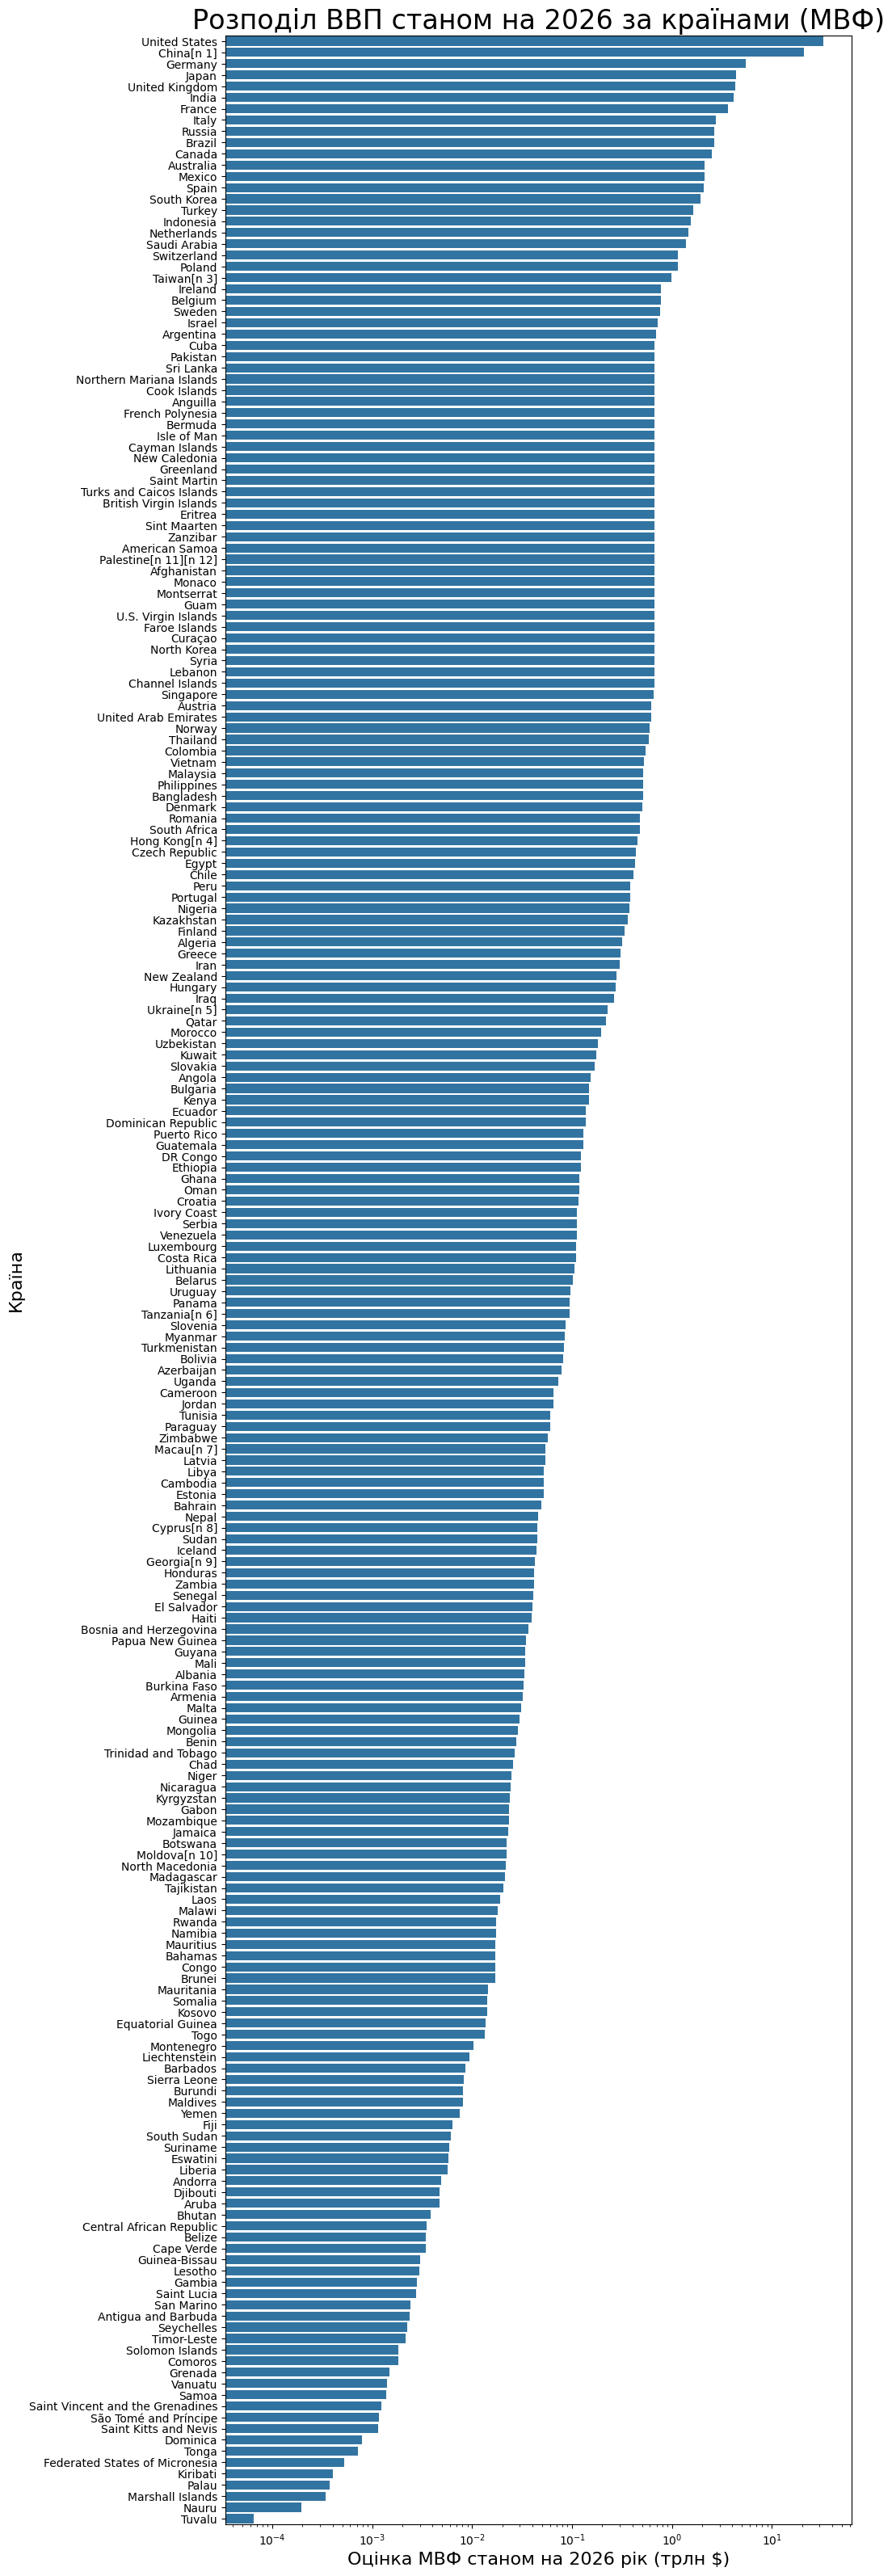

In [457]:
import seaborn as sns
import matplotlib.pyplot as plt

copy = df.copy()

copy['IMF_2026_trln'] = copy['IMF_2026'] / 1e6

def plot_1(scale):

  plt.figure(figsize = (10,40))

  sns.barplot(
      data = copy.sort_values(by = 'IMF_2026',ascending=False),
      y = 'Country',
      x = 'IMF_2026_trln'
  )
  plt.xscale(scale) # через те що певна кількість країн має ВВП менше 1 трлн - для осі x використав логарифмічну шкалу

  plt.title(
      "Розподіл ВВП станом на 2026 за країнами (МВФ)", fontdict={"fontsize": 24}
  )
  plt.xlabel(
      "Оцінка МВФ станом на 2026 рік (трлн $)", fontdict={"fontsize": 16}
      )
  plt.ylabel(
      "Країна", fontdict={"fontsize": 16}
      )

  plt.show()

plot_1('log')

Навіть з логарифмічною шкалою розрив доволі помітний, США та Китай - лідери, після них Німеччина, Японія, Британія, плавне спадання починається з Франції, а в кінці макроекономіки, яких на лінійній шкалі не видно зовсім (нижче)

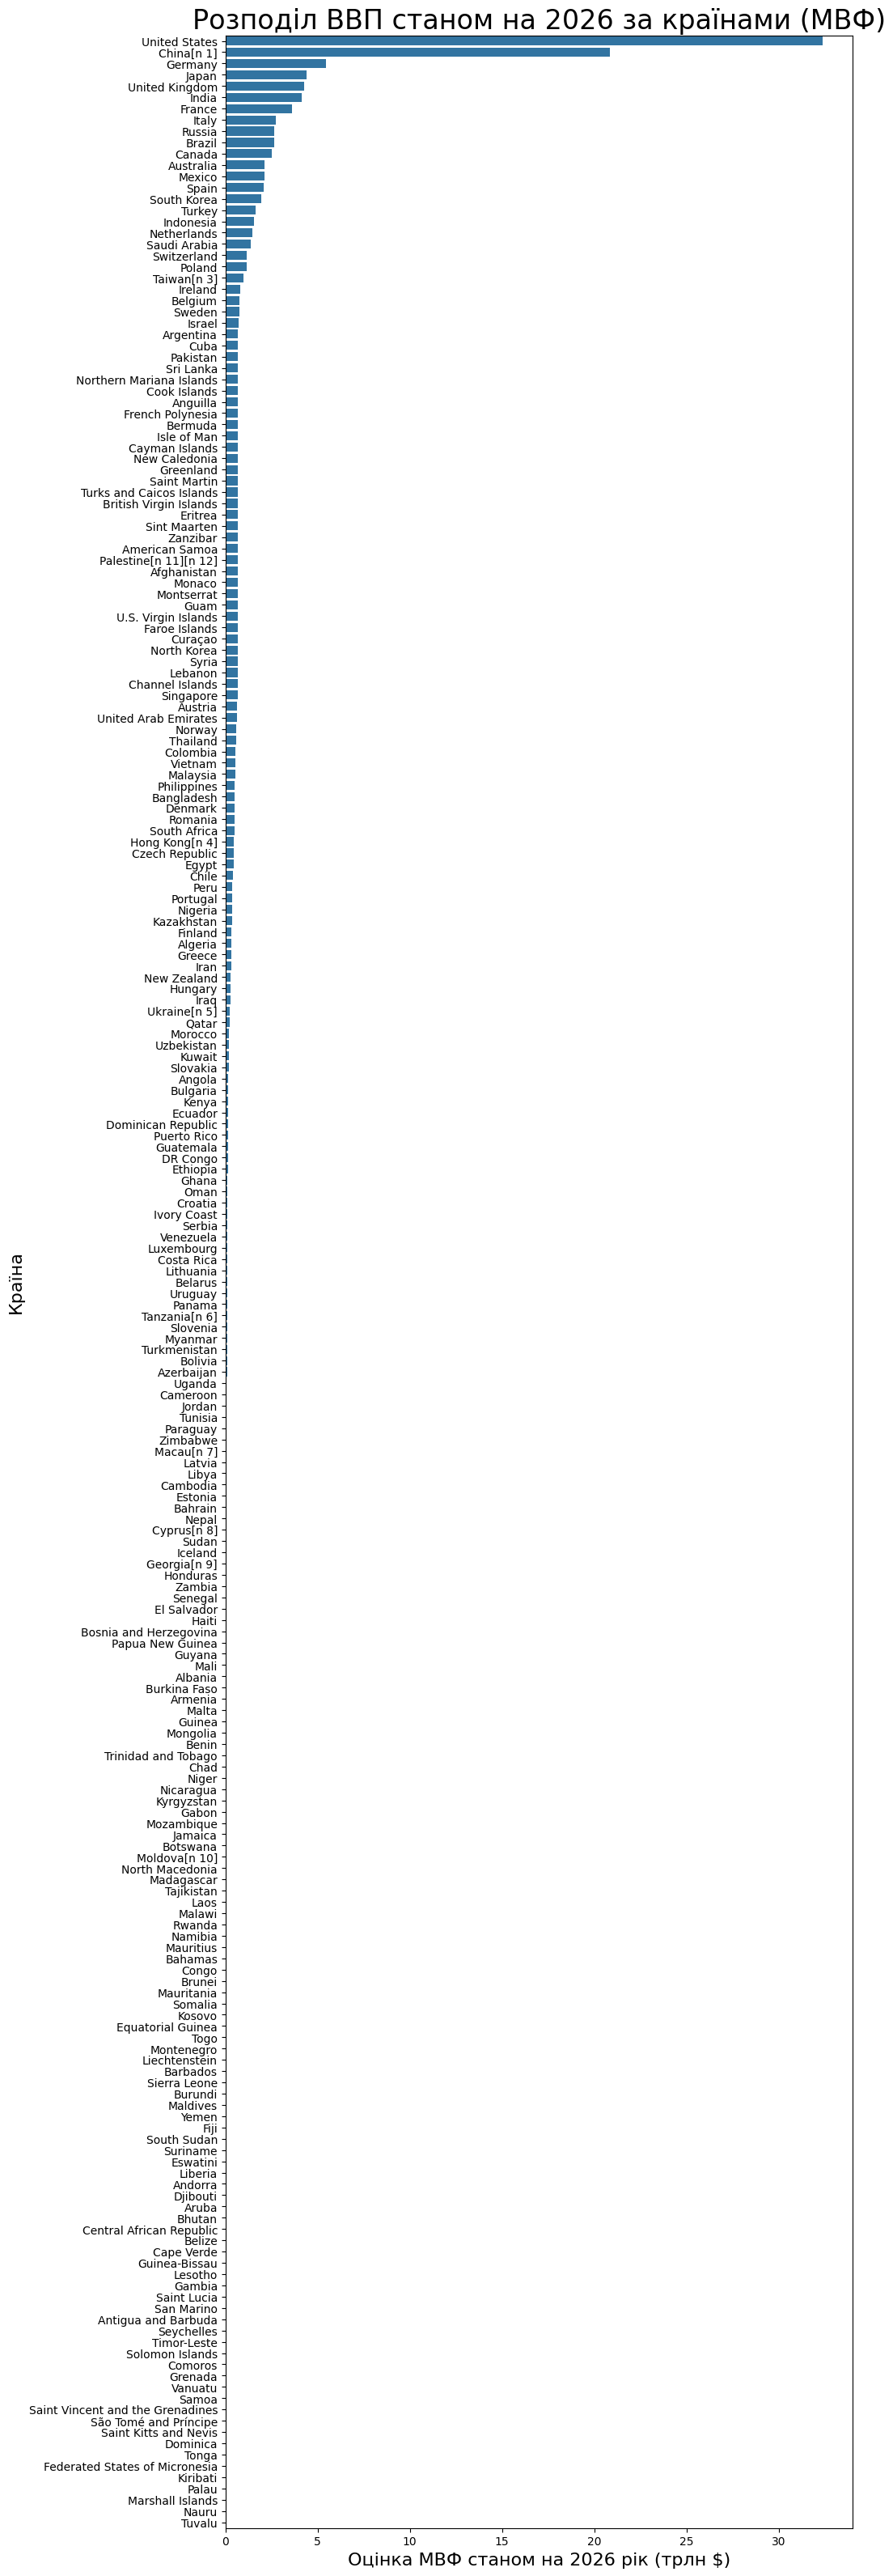

In [458]:
plot_1('linear')

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [459]:
for i in df.columns[1:4]:
  df[f"{i}_precent"] = (df[i]/df[i].sum()*100)

In [460]:
data = df[['Country','IMF_2026_precent','World_bank_2025_precent', 'UN_2024_precent']]
melted = data.melt(
    id_vars='Country',
    value_vars=['Country','IMF_2026_precent','World_bank_2025_precent', 'UN_2024_precent'],
    value_name='Частка (%)',
    var_name='Рік'
    )

15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

In [461]:
melted['Рік'] = melted['Рік'].replace({
    'IMF_2026_precent': '2026',
    'World_bank_2025_precent': '2025',
    'UN_2024_precent': '2024'
}).astype(int)

In [462]:
top_10 = melted[melted['Рік']==2024].sort_values(by = 'Частка (%)',ascending=False).head(10)['Country'].to_list()


In [463]:
data = melted[melted['Country'].isin(top_10)]

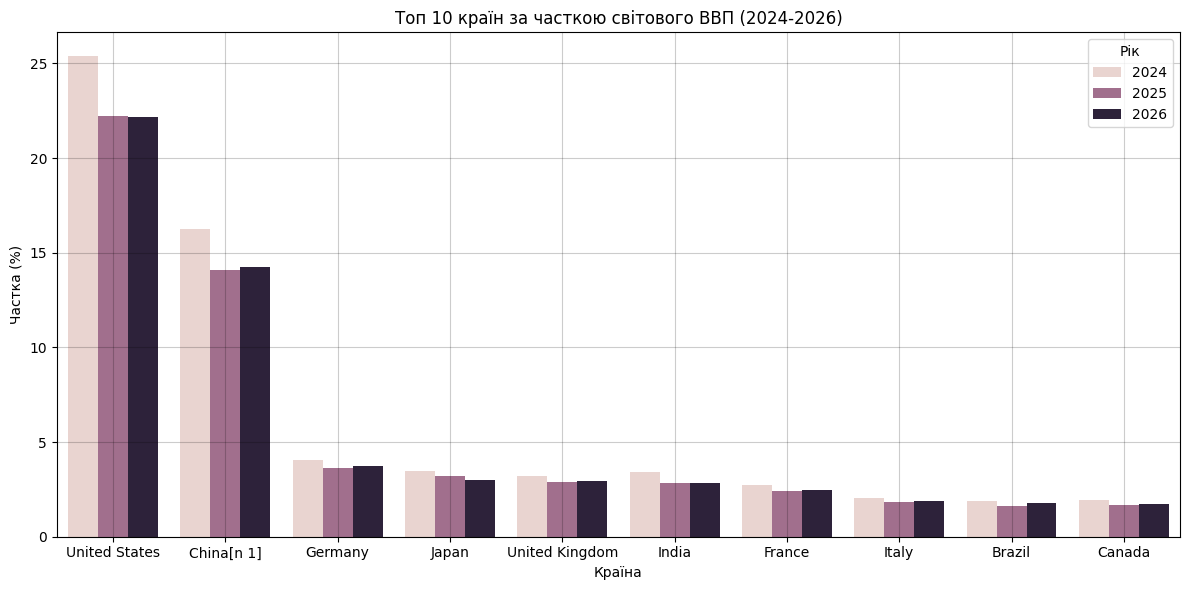

In [464]:
plt.figure(
    figsize=(12,6)
)

sns.barplot(data=data, x = 'Country', y = 'Частка (%)', hue='Рік')

plt.xlabel('Країна')
plt.title('Топ 10 країн за часткою світового ВВП (2024-2026)')

plt.grid(alpha = 0.2, color = 'black')
plt.tight_layout()
plt.show()


Серед наведених стабільний спад демонструють лише США, Японія та Індія, чиї стовпчики послідовно зменшуються щороку. Жодна з представлених економік не показує стабільного зростання, оскільки решта показує просідання у 2025 році з подальшим підйомом.